In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline
from pprint import pprint

## Motivation for using word embeddings

The 2 biggest problem with n gram language models are:
1. Curse of Dimensionality:

    Let's say out vocab V has |V| = $10^5$ for a 10-gram model.
    Then we will have $10^{50}$ weights in the nn to tune.

2. Semantics:

    let's say training set has : 'A cat was eating fish'

    The test set having : 'The dog is eating _' 
    
    An n-gram model will fail to give any probabilty to this test set even though its trained on a semantically similar sentence. 

## Solution

If we embed the word into 30 dim space. 

Context has total of 9 vectors with 30 dimensions each.

We combine them to create a single vector : $9*30=270$ 


In [2]:
words = open("Indian.txt",'r').read().splitlines()
words[:8]

['Aaban',
 'Aabharan',
 'Aabhas',
 'Aabhat',
 'Aabheer',
 'Abheer',
 'Aabher',
 'Aabi']

In [3]:
len(words)

53982

In [4]:
chars= sorted(set([ch.lower() for w in words for ch in w]))
itos = {0:'.'}
for i, ch in enumerate(chars):
    itos[i+1]=ch
stoi = {}
for i,ch in itos.items():
    stoi[ch]=i


In [5]:
# Building the training data set
# We consider 3 chars to be the context for predicting the next char

# This is the format in which we want the (x,y) : ([ix1, ix2, ix3] , iy)
context_length = 3
x = []
y = []
for w in words[:1]:
    w = w.lower()
    context = [0] * context_length
    w = w + '.'
    for ch in w:
        x.append(context.copy())
        y.append(stoi[ch])
        context[:-1] = context[1:]
        context[-1] = stoi[ch]

x = torch.tensor(x)
y = torch.tensor(y)

In [6]:
# Now we have to embed these character indexes into vectors
# C is the matrix that contains the vector embeddings corresponding to the characters
# These params are shared for all n-1 input characters in the model
emb_dims = 2
g = torch.Generator().manual_seed(2147483647) 
C = torch.randn((27,emb_dims),generator=g)

(-3.5, 3.5)

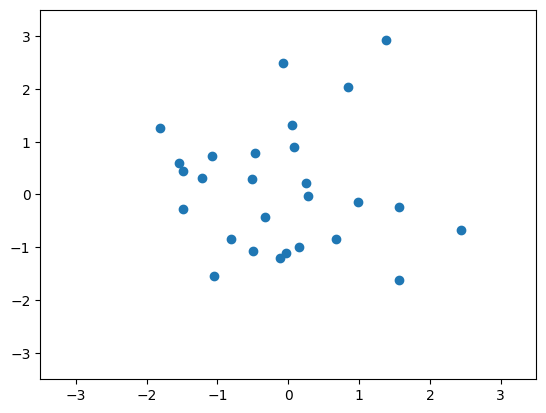

In [7]:
# Useful only for 2 dimensional embeddings
plt.scatter(C[:,0],C[:,1])
plt.xlim(-3.5,3.5)
plt.ylim(-3.5,3.5)

In [8]:
# Now we will convert the indexes to embedding using these weights in C
xenc = F.one_hot(x,num_classes=27).float()
emb = xenc@C

In [9]:
# Better approach
emb = emb.view(-1,(emb_dims*context_length))
emb

tensor([[ 1.5674, -0.2373,  1.5674, -0.2373,  1.5674, -0.2373],
        [ 1.5674, -0.2373,  1.5674, -0.2373, -0.0274, -1.1008],
        [ 1.5674, -0.2373, -0.0274, -1.1008, -0.0274, -1.1008],
        [-0.0274, -1.1008, -0.0274, -1.1008,  0.2859, -0.0296],
        [-0.0274, -1.1008,  0.2859, -0.0296, -0.0274, -1.1008],
        [ 0.2859, -0.0296, -0.0274, -1.1008, -1.2199,  0.3031]])

In [10]:
# Before passing through this layer, we will concatenate the embedding in a single context
# x_emb = []
# for (e1,e2,e3) in (emb):
#     x_emb.append(([e1[0],e1[1],e2[0],e2[1],e3[0],e3[1]]))
# x_emb = torch.tensor(x_emb)
# print(x_emb)


# Motivation For a Hidden Layer

## Thought 1 : NO HIDDEN LAYER
Let's not use a hidden layer, and instead we directly compute the scores for the next characters.

The 3 embeddings are represented as $e_1 , e_2, e_3$. (Each is a vector of 2 dimensions in our case)

The input $x = [e_1,e_2,e_3]$ of shape (1,6) 

Let W be the weights for the next layer. A matrix of size (6,27) Which can be divided into 3 matrices of dimensions (2,27) : $W = [w_1^{T} , w_2^{T}, w_3^{T}]^{T}$

The output is then calculated as $z = xW + b$

Since this is a linear combination, we can rewrite z as : $z = e_1w_1 + e_2w_2 + e_3w_3 + b$

### What does this signify?

This shows that the characters in their positions are contributing individually and independently to the probabilities of the next character.

Ex.

The training set includes the word care: "car -> e". This causes the weights joining the (input char at position [1,2,3] = [c,a,r]) to the 5th node (e) in output to be high. 

Now we are trying to calulate the prob scores of next char when the context is "cat".

The $z_e$ will be high because "c" at position 1 and "a" at position 2 pushes e to be the next char. Eventhough the training should incentivize "e" only when we see "car" together.

### Conclusion:
We can't merely have linear relation between input and outputs. We need the model to capture relations between the characters at different positions.


## How does adding a hidden layer let us capture non linear relations between chars at different positions

Let's add a hidden layer. Let it have 100 nodes.

The 3 embeddings are represented as $e_1 , e_2, e_3$. (Each is a vector of 2 dimensions in our case)

The input $x = [e_1,e_2,e_3]$ of shape (1,6) 

Let $W_1$ be the weights for the next layer. A matrix of size (6,100) Which can be divided into 3 matrices of dimensions (2,27) : $W = [w_1^{T} , w_2^{T}, w_3^{T}]^{T}$

The intermediate results is then calculated as $z = xW + b$ , shape of z is (1,100)

In the next layer we get our outputs by the equation:

$p = z\theta +b_2$ , where $\theta$ has shape (100,27).

$p = (e_1w_1 + e_2w_2 + e_3w_3 + b)\theta +b_2$

$p = e_1(w_1\theta) + e_2(w_2\theta) + e_3(w_3\theta) + (b\theta +b_2)$

We can clearly notice that the output is effectively a linear combination of the input chars. From the above conclusion, a hidden layer with no non-linearity is redundant.

### Let's add non-linear activation function

Intiutively, its clear that an AND function would work magnificiently in every node of the hidden layer.

For example, let's say node 14 of the hidden layer would activate for x = "lov" by having weights from the previous layer such that the input having embs of those chars (l@1, o@2, v@3) increases the value of the node ; and the node itself being activated using an AND function. 

Similar is the effect of $tanh$ and $b_i$ combined. It gives an output between $[-1,1]$. Let x = "lov" = $[e_1,e_2,e_3]$ and $b_14 = -14$. Let $W_{1,14}$ $W_{2,14}$ be such that when multiplying $e_1$ with them, they produce a value of 5. Similar be the case for $W_{3,14}$, $W_{4,14}$ for $e_2$ and $W_{5,14}$, $W_{6,14}$ for $e_3$.

In such a case, the node 14 will only activate when it gets all three chars in the order specified. Since $tanh(5+5+5-14) = tanh(1) > 0$. While if we get x = "los", the node wont get activated assuming the $W_{5,14}$, $W_{6,14}$ for "s" gives a value less than 4.

In [11]:
# We want to create a hidden layer in between the input (individual tensors) and the output (score for each next character)
# Arbitrarily we choose the hidden layer to have 100 nodes
W = torch.randn((6,100),generator=g)
b = torch.randn(100,generator=g)

x_hide = torch.tanh(emb @ W + b)

In [12]:
# Now the last layer, in which these 100 nodes are the input and the score for each character is the op
W1 = torch.randn((100,27),generator=g)
b1 = torch.randn(27,generator=g)

logits = x_hide @ W1 + b1

#Converting it into probailities
counts = logits.exp()


p = counts/counts.sum(1, keepdim=True)

In [14]:
# Now let's find the loss for these parameters
print(p)

tensor([[2.5218e-09, 2.0283e-10, 2.1459e-04, 8.7084e-11, 2.3119e-12, 1.5213e-14,
         9.3108e-19, 8.3789e-06, 4.5310e-09, 1.4206e-01, 8.5761e-01, 5.2101e-12,
         1.7917e-10, 1.8797e-10, 9.4676e-05, 1.0823e-10, 3.5813e-09, 1.0154e-07,
         2.7855e-07, 2.6851e-09, 2.2371e-11, 3.2192e-09, 4.8182e-12, 2.0270e-11,
         9.4408e-06, 5.6799e-09, 3.4497e-06],
        [5.6182e-11, 2.6391e-09, 1.7303e-02, 1.4218e-12, 6.2870e-12, 3.7403e-15,
         3.4932e-14, 2.9416e-06, 3.2327e-09, 4.0940e-03, 9.7848e-01, 4.9434e-12,
         5.6288e-08, 3.3476e-10, 1.5190e-07, 1.1775e-04, 1.2499e-06, 1.2366e-08,
         2.1262e-08, 7.7545e-08, 1.9874e-08, 5.4306e-07, 3.5709e-11, 4.8662e-13,
         1.9463e-10, 1.6596e-10, 1.5980e-09],
        [9.4762e-09, 3.7218e-07, 2.7177e-03, 8.5845e-11, 2.4600e-10, 1.0599e-09,
         3.0199e-10, 1.6760e-03, 3.5411e-06, 8.8491e-05, 9.9191e-01, 3.6604e-06,
         2.5090e-04, 9.3406e-08, 1.5244e-04, 1.6698e-03, 9.4413e-04, 8.6227e-07,
         5.7695e-